In [8]:
!pip install numpy; matplotlib
import numpy as np
import matplotlib.pyplot as plt

/bin/bash: line 1: matplotlib: command not found


In [13]:
a = 1.4
b = 0.3
p, q = 0.1, 0.1
ps, qs = [], []

for i in range(10000):
    p_new = 1 - a*p**2 + q
    q_new = b*p

    p, q = p_new,q_new

    if i > 1000: 
        ps.append(p)
        qs.append(q)

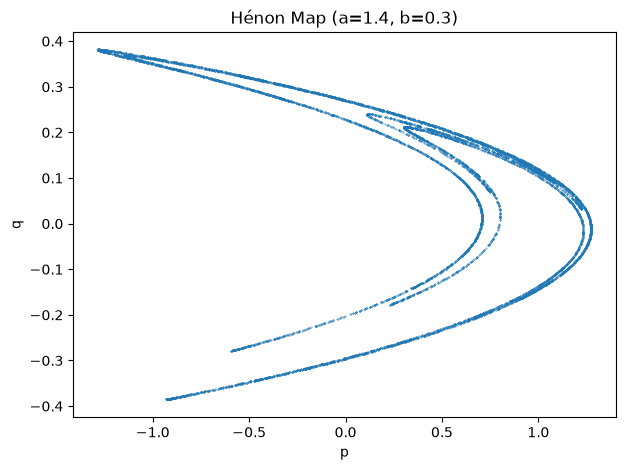

In [14]:
plt.figure(figsize=(7, 5))
plt.scatter(ps, qs, s=0.1)
plt.xlabel("p")
plt.ylabel("q")
plt.title(f"Hénon Map (a={a}, b={b})")
plt.show()

In [25]:
def generate_orbit(r, n_points=1000):
    x, y = np.random.uniform(0, 1, size=2)

    orbit = []

    for i in range(n_points):
        x_new = (x + r*y*(1-y)) % 1
        y_new = (y + r*x_new*(1-x_new)) % 1

        x, y = x_new, y_new

        orbit.append([x, y])

    return np.array(orbit)


(1000, 2)


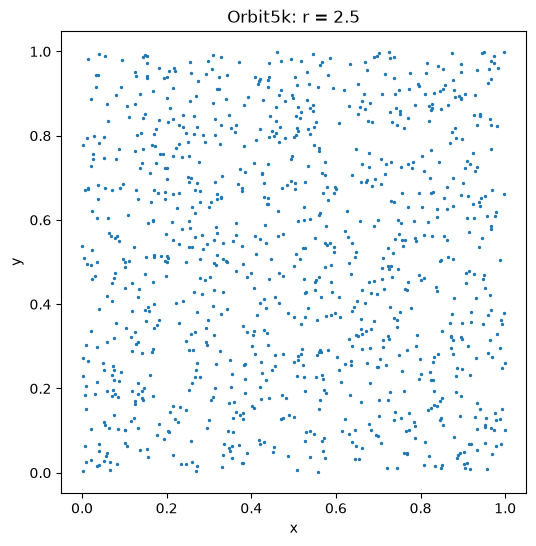

(1000, 2)


In [26]:
orbit = generate_orbit(r=2.5)

print(orbit.shape)

plt.figure(figsize=(6, 6))
plt.scatter(orbit[:, 0], orbit[:, 1], s=2)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Orbit5k: r = 2.5")
plt.show()
orbit = generate_orbit(r=2.5)

print(orbit.shape)

In [27]:

r_values = [2.5, 3.5, 4.0, 4.1, 4.3]

n_orbits = 1000
n_points = 1000

X = []
y = []

for label, r in enumerate(r_values):

    for i in range(n_orbits):
        orbit = generate_orbit(r, n_points)

        X.append(orbit)
        y.append(label)

X = np.array(X)
y = np.array(y)


In [28]:
print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)

for label, r in enumerate(r_values):
    print(f"Class {label} (r={r}):", np.sum(y == label))

Dataset shape: (5000, 1000, 2)
Labels shape: (5000,)
Class 0 (r=2.5): 1000
Class 1 (r=3.5): 1000
Class 2 (r=4.0): 1000
Class 3 (r=4.1): 1000
Class 4 (r=4.3): 1000


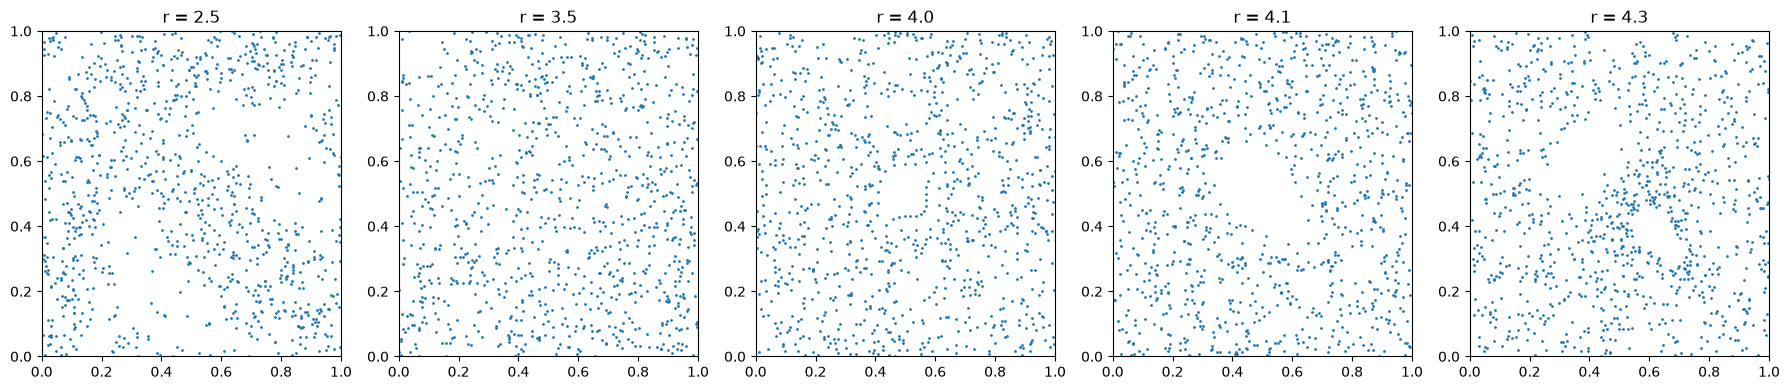

In [29]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for label, ax in enumerate(axes):
    ax.scatter(
        X[label * 1000, :, 0],
        X[label * 1000, :, 1],
        s=1
    )
    ax.set_title(f"r = {r_values[label]}")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [30]:
np.savez_compressed(
    "orbit5k.npz",
    X=X,
    y=y,
    r_values=np.array(r_values)
)